# Обучение классических классификаторов

Используем подготовленные данные из `02_preparation.ipynb`. Сравним классические модели для двух целей: CLASS — паттерн КТГ, NSP — оценка состояния. Для каждой цели обучается отдельный классификатор. Эксперименты сохраняются в MLflow.

Train используется для обучения, validation — для сравнения и выбора настроек. В конце пункта 6 baseline и выбранные классические модели оцениваются на test. Этот набор не используется для подбора параметров.

## 1. Загрузка подготовленных данных

Загрузим train.csv, validation.csv и test.csv из `runtime/data/prepared/`. Отделим 21 входной признак от CLASS и NSP. Идентификаторы удалены при подготовке; отсутствие пересечения исследований проверено до их удаления.

Результат: входы и две цели для каждой части выборки. Test в расчётах качества на этом этапе не используется.

In [1]:
from experiments.settings import ExperimentSettings

import pandas as pd

settings = ExperimentSettings()

prepared_dir = settings.prepared_dir
splits = {name: pd.read_csv(prepared_dir / f"{name}.csv") for name in ["train", "validation", "test"]}

train_df = splits["train"]
validation_df = splits["validation"]
test_df = splits["test"]

pd.DataFrame({name: {"Строки": len(part), "Колонки": len(part.columns)} for name, part in splits.items()}).T

,Строки,Колонки
train,1266,23
validation,421,23
test,421,23


In [2]:
from experiments.constants import (
    class_mapping,
    nsp_mapping,
    target_cols,
)

### Отделение входов и целей

CLASS и NSP — две цели; остальные колонки используются как входы. Для каждой части выделим таблицу входных признаков X. Целевые значения берём из соответствующих колонок CLASS и NSP при обучении и оценке.

In [3]:
feature_cols = train_df.columns.drop(target_cols).tolist()

X_train = train_df[feature_cols]
X_validation = validation_df[feature_cols]
X_test = test_df[feature_cols]



print(f"Входных признаков: {len(feature_cols)}")
display(X_train.head())

Входных признаков: 21


,LB,AC,FM,UC,ASTV,MSTV,ALTV,MLTV,DL,DS,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,duration
0,132.0,4.0,0.0,4.0,17.0,2.1,0.0,10.4,2.0,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,627.0
1,133.0,2.0,0.0,5.0,16.0,2.1,0.0,13.4,2.0,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,602.0
2,134.0,2.0,0.0,6.0,16.0,2.4,0.0,23.0,2.0,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,781.0
3,132.0,4.0,0.0,5.0,16.0,2.4,0.0,19.9,0.0,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,614.0
4,122.0,0.0,0.0,0.0,83.0,0.5,6.0,15.6,0.0,0.0,...,62.0,130.0,0.0,0.0,122.0,122.0,123.0,3.0,1.0,617.0


## 2. Метрики и настройка MLflow

### Как оценивается качество

Для каждой модели сравним истинные метки с предсказаниями на train и validation. Для CLASS и NSP показатели рассчитываются отдельно.

- **Macro-F1** — основная метрика. F1 объединяет precision и recall; macro-F1 усредняет F1 по классам с одинаковым весом, чтобы частый класс не скрывал ошибки на редких.
- **Weighted-F1** — средний F1 по классам с весами, равными их долям в выборке. Для нашей задачи это дополнительная метрика: частый класс Normal влияет на неё сильнее, поэтому хорошее распознавание Normal может скрывать ошибки на редких Suspect и Pathologic. Основными ориентирами остаются macro-F1 и ошибки по этим категориям; weighted-F1 используем для дополнительного сравнения моделей. Если macro-F1 растёт, а weighted-F1 падает, возможно, модель лучше определяет редкие классы за счёт частых. В этом случае проверяем матрицу ошибок, чтобы увидеть, какие категории стали распознаваться хуже.
- **Accuracy** — доля правильных предсказаний. Используется как дополнительный показатель из-за дисбаланса классов.
- **Precision по классу** — какая доля предсказаний этого класса верна.
- **Recall по классу** — какую долю записей этого класса модель обнаружила. Для Pathologic он показывает долю найденных патологических случаев.

Создадим общую функцию оценки с помощью sklearn.metrics: accuracy_score, f1_score и classification_report. Матрица ошибок покажет, какие категории перепутаны. Разница между качеством train и validation поможет заметить переобучение.

### Как сохраняются эксперименты

Подключимся к локальному MLflow, запущенному командой `just mlflow-start`. Создадим один эксперимент для классических моделей. Каждый запуск модели для одной цели с конкретными настройками будет отдельным run.

Внутри run сохраним:

- цель (CLASS или NSP), тип модели, параметры, seed и список входных признаков;
- метрики с префиксами train_ и validation_, включая accuracy, macro-F1, weighted-F1 и precision/recall/F1 по классам;
- отчёты классификации и матрицы ошибок как артефакты;
- обученный Pipeline вместе со scaler для исходных и выбранных моделей. Во время подбора сохраняем параметры, метрики и отчёты; сами модели всех промежуточных попыток в MLflow не сохраняем.

Для регистрации используем mlflow.start_run, log_params, log_metrics и сохранение артефактов. Это позволит сравнивать запуски в интерфейсе MLflow и восстановить выбранную модель. Test в этих экспериментах не оценивается.

Результат: одинаковая оценка всех моделей и сохранённые параметры, метрики и артефакты каждого эксперимента.

### Подключение и общие настройки

Адрес MLflow определяется портом из .env. Фиксируем seed и соответствие кодов названиям классов, чтобы отчёты всех моделей имели одинаковый порядок категорий.

### Служебная настройка логов и локальных запросов

In [4]:
import logging
import os

os.environ["MLFLOW_LOGGING_LEVEL"] = "WARNING"
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
os.environ["MLFLOW_PRINT_MODEL_URLS_ON_CREATION"] = "false"

# Убираем служебные INFO даже при повторном выполнении ячейки.
for name in ["mlflow", "mlflow.agent.hint", "mlflow.utils.uv_utils", "mlflow.utils.environment"]:
    logging.getLogger(name).setLevel(logging.WARNING)

# Скрываем два служебных предупреждения MLflow
logging.getLogger("mlflow.sklearn").addFilter(
    lambda record: not record.getMessage().startswith(
        "Saving scikit-learn models in the pickle or cloudpickle format",
    ),
)
logging.getLogger("mlflow.utils.environment").addFilter(
    lambda record: not record.getMessage().startswith("Failed to resolve installed pip version."),
)

# Локальные запросы не должны проходить через системный прокси.
for variable in ["NO_PROXY", "no_proxy"]:
    os.environ[variable] = ",".join(filter(None, [os.environ.get(variable, ""), "localhost", "127.0.0.1"]))

In [5]:
import subprocess
import typing

import mlflow
import mlflow.sklearn
from pydantic import BaseModel
from sklearn.base import BaseEstimator
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from classifier.settings import PROJECT_ROOT

subprocess.run(["just", "mlflow-start"], cwd=PROJECT_ROOT, check=True)
mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
experiment = mlflow.set_experiment(settings.mlflow_experiment_name)
print(f"MLflow: {mlflow.get_tracking_uri()}, эксперимент: {experiment.name}")

# Сохраняем окружение модели из lock-файла вместе с группами обучения и MLflow.
model_requirements = subprocess.run(
    ["uv", "export", "--frozen", "--no-dev", "--group", "data", "--group", "tracking",
     "--no-hashes", "--no-header", "--no-emit-project", "--no-annotate"],
    cwd=PROJECT_ROOT, check=True, capture_output=True, text=True,
).stdout.splitlines()

Порт 5001 уже занят — повторный запуск пропущен
MLflow: http://127.0.0.1:5001, эксперимент: classical_classifiers


### Расчёт метрик

Функция принимает истинные метки, предсказания и название цели. Возвращает accuracy, macro-F1, weighted-F1, отчёт по каждому классу и матрицу ошибок. Строки матрицы — истинные категории, столбцы — предсказанные. Если класс не предсказывается, его precision и F1 записываются как 0; это позволяет оценить и DummyClassifier.

In [6]:
from experiments.constants import ClassificationTarget


class ClassificationEvaluation(BaseModel):
    metrics: dict[str, float]
    report: dict[str, typing.Any]
    confusion: list[list[int]]
    labels: list[str]


def evaluate_classifier(
    y_true: pd.Series, y_pred: typing.Any, target: ClassificationTarget,
) -> ClassificationEvaluation:
    names = {ClassificationTarget.CLASS: class_mapping, ClassificationTarget.NSP: nsp_mapping}[target]
    labels = list(names)
    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=list(names.values()),
        output_dict=True,
        zero_division=0,
    )
    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
    }
    for class_name in names.values():
        for metric in ["precision", "recall", "f1-score"]:
            metric_name = "f1" if metric == "f1-score" else metric
            metrics[f"{class_name}_{metric_name}"] = float(report[class_name][metric])
    return ClassificationEvaluation(
        metrics=metrics,
        report=report,
        confusion=confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        labels=list(names.values()),
    )

### Обучение и регистрация одного запуска

Функция обучает переданную модель на train, оценивает train и validation и сохраняет результаты в отдельном run. Цель выбирается параметром target. В MLflow записываются параметры модели, seed, список признаков, метрики, JSON-отчёты и матрицы ошибок. Обученная модель сохраняется целиком, включая scaler, если передан Pipeline. Возвращаются модель, результаты оценки и идентификатор run для последующего сравнения.

In [7]:
def train_and_log_classifier(
    model: BaseEstimator, target: ClassificationTarget, run_name: str, *, save_model: bool = True,
) -> tuple[
    BaseEstimator,
    dict[str, ClassificationEvaluation],
    str,
]:
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({"target": target.value, "model_type": type(model.named_steps["classifier"]).__name__})
        mlflow.log_params(
            {"target": target.value, "random_state": settings.random_state, **model.get_params(deep=True)},
        )
        mlflow.log_dict(
            {
                "features": feature_cols,
                "target_mapping": {ClassificationTarget.CLASS: class_mapping, ClassificationTarget.NSP: nsp_mapping}[
                    target
                ],
            },
            "input_schema.json",
        )

        model.fit(X_train, train_df[target.value])
        evaluations = {}
        for split_name, inputs, targets in [
            ("train", X_train, train_df[target.value]),
            ("validation", X_validation, validation_df[target.value]),
        ]:
            evaluation = evaluate_classifier(targets, model.predict(inputs), target)
            evaluations[split_name] = evaluation
            mlflow.log_metrics({f"{split_name}_{key}": value for key, value in evaluation.metrics.items()})
            mlflow.log_dict(evaluation.report, f"{split_name}/classification_report.json")
            mlflow.log_dict(
                {"labels": evaluation.labels, "matrix": evaluation.confusion},
                f"{split_name}/confusion_matrix.json",
            )
        if save_model:
            mlflow.sklearn.log_model(
                model, name="model", input_example=X_train.head(5), serialization_format="cloudpickle",
                pip_requirements=model_requirements,
            )
        return model, evaluations, run.info.run_id

## 3. Базовый ориентир: DummyClassifier

Для обеих целей обучим DummyClassifier, который всегда выбирает самый частый класс train. Оценим его на validation по тем же метрикам, по которым будем оценивать и остальные модели.

Результат: исходный уровень качества, с которым сравниваются обучаемые классификаторы.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

trained_models = {}
model_evaluations = {}
run_ids = {}

for target in ClassificationTarget:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DummyClassifier(strategy="most_frequent", random_state=settings.random_state)),
    ])
    key = (target, "DummyClassifier")
    trained_models[key], model_evaluations[key], run_ids[key] = train_and_log_classifier(
        model, target, f"{target.value}_DummyClassifier",
    )

display(pd.DataFrame([
    {"Цель": target.value, "Модель": name, **evaluation["validation"].metrics}
    for (target, name), evaluation in model_evaluations.items()
])[["Цель", "Модель", "accuracy", "macro_f1", "weighted_f1"]].round(4))

🏃 View run CLASS_DummyClassifier at: http://127.0.0.1:5001/#/experiments/1/runs/d5986a39e1294df384d121f31f879017
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_DummyClassifier at: http://127.0.0.1:5001/#/experiments/1/runs/c3ce51eaf6064c818d6db30a29f1e2c5
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,Цель,Модель,accuracy,macro_f1,weighted_f1
0,CLASS,DummyClassifier,0.2708,0.0426,0.1154
1,NSP,DummyClassifier,0.7791,0.2919,0.6824


**Вывод.** DummyClassifier всегда выбирает B для CLASS и Normal для NSP. Macro-F1 на validation: 0,043 и 0,292 соответственно. Weighted-F1 составляет 0,115 для CLASS и 0,682 для NSP: частые категории имеют больший вес, поэтому значения выше macro-F1. Accuracy для NSP достигает 77,91%, хотя остальные категории модель не обнаруживает — это показывает ограничение accuracy при дисбалансе.

## 4. Обучение классических моделей

Обучим LogisticRegression, LinearSVC и RandomForestClassifier отдельно для CLASS и NSP. LinearSVC — линейный классификатор, который разделяет классы с помощью гиперплоскостей.

Для каждой модели создадим Pipeline со StandardScaler. Масштабирование важно для линейных моделей; для случайного леса обычно не требуется, но позволяет использовать одинаковую схему подготовки. Scaler обучается только на train.

В словаре зададим три классификатора. В цикле для каждой цели создадим независимую копию классификатора и новый scaler, обучим pipeline и сохраним результаты в MLflow. Используем начальные настройки без подбора параметров; max_iter увеличен для сходимости линейных моделей.

Результат: шесть обученных pipeline и их оценки на train и validation.

В итоговой таблице:
- train_macro_f1 — средний F1 по классам на обучающих данных;
- validation_macro_f1 — та же метрика на данных, которые модель не использовала при обучении;
- train_weighted_f1 и validation_weighted_f1 — средний F1 с учётом частоты классов на соответствующей выборке;
- validation_accuracy — доля правильных предсказаний на validation, без уравнивания вклада классов.

Сравнение train_macro_f1 и validation_macro_f1 показывает разрыв между качеством на обучающих и новых данных. Macro-F1 учитывает редкие классы наравне с частыми, а accuracy сильнее зависит от частых классов.

In [9]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

classifiers = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=settings.random_state),
    "LinearSVC": LinearSVC(max_iter=10000, random_state=settings.random_state),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=200, random_state=settings.random_state, n_jobs=-1,
    ),
}

for target in ClassificationTarget:
    for model_name, classifier in classifiers.items():
        print(f"Обучение {model_name}, цель {target.value}")
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", clone(classifier)),
        ])
        key = (target, model_name)
        trained_models[key], model_evaluations[key], run_ids[key] = train_and_log_classifier(
            model, target, f"{target.value}_{model_name}",
        )

initial_results = pd.DataFrame([
    {
        "Цель": target.value,
        "Модель": model_name,
        "train_macro_f1": evaluations["train"].metrics["macro_f1"],
        "validation_macro_f1": evaluations["validation"].metrics["macro_f1"],
        "validation_accuracy": evaluations["validation"].metrics["accuracy"],
        "train_weighted_f1": evaluations["train"].metrics["weighted_f1"],
        "validation_weighted_f1": evaluations["validation"].metrics["weighted_f1"],
    }
    for (target, model_name), evaluations in model_evaluations.items()
])
display(initial_results.round(4))

Обучение LogisticRegression, цель CLASS
🏃 View run CLASS_LogisticRegression at: http://127.0.0.1:5001/#/experiments/1/runs/5a3e569f86cf4aa388b42dd29dbcfd4c
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Обучение LinearSVC, цель CLASS
🏃 View run CLASS_LinearSVC at: http://127.0.0.1:5001/#/experiments/1/runs/7f8015c9a7e94a65bad7e6dec9611dd6
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Обучение RandomForestClassifier, цель CLASS
🏃 View run CLASS_RandomForestClassifier at: http://127.0.0.1:5001/#/experiments/1/runs/161891b000e34556a19d79067514c3de
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Обучение LogisticRegression, цель NSP
🏃 View run NSP_LogisticRegression at: http://127.0.0.1:5001/#/experiments/1/runs/e51599a5019b4a18a12bd1351475b7fc
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Обучение LinearSVC, цель NSP
🏃 View run NSP_LinearSVC at: http://127.0.0.1:5001/#/experiments/1/runs/ceca631ceb9e4f1e892abfb1fd106828
🧪 View experimen

,Цель,Модель,train_macro_f1,validation_macro_f1,validation_accuracy,train_weighted_f1,validation_weighted_f1
0,CLASS,DummyClassifier,0.0428,0.0426,0.2708,0.1167,0.1154
1,NSP,DummyClassifier,0.2912,0.2919,0.7791,0.6777,0.6824
2,CLASS,LogisticRegression,0.8259,0.6984,0.8005,0.8687,0.7963
3,CLASS,LinearSVC,0.7753,0.6691,0.7672,0.8253,0.7605
4,CLASS,RandomForestClassifier,1.0000,0.7798,0.8694,1.0000,0.8581
5,NSP,LogisticRegression,0.8229,0.7609,0.8955,0.9002,0.8866
6,NSP,LinearSVC,0.7995,0.7599,0.8931,0.8908,0.8843
7,NSP,RandomForestClassifier,1.0000,0.8649,0.9382,1.0000,0.9358


**Вывод.**
- Все три классификатора превзошли DummyClassifier по macro-F1 и weighted-F1 на validation.
- RandomForest получил лучший начальный результат: macro-F1 — 0,780 для CLASS и 0,865 для NSP; weighted-F1 — 0,858 и 0,936 соответственно.
- Глубина леса оставлена неограниченной, поскольку использовано стандартное max_depth=None. Это исходная настройка для сравнения, а не результат подбора. LogisticRegression и LinearSVC также используют исходное C=1; сравнение настроенных моделей выполняется после подбора параметров.

## 5. Сравнение моделей на validation

Составим отдельные таблицы метрик для CLASS и NSP. Рассмотрим матрицы ошибок и precision/recall по классам: какие категории путаются и насколько хорошо обнаруживается Pathologic. Сравним качество train и validation, чтобы заметить признаки переобучения.

Результат: обоснованный выбор моделей для подбора параметров и краткий вывод об их сильных и слабых сторонах.

### Общее качество и разрыв между train и validation

Для каждой цели сравним macro-F1 и weighted-F1 на train и validation, а также accuracy на validation. На графиках сравним macro-F1 на train и validation. Weighted-F1 оставим в таблице: сравниваем его с baseline и другими моделями на той же выборке; он дополняет оценку, но не заменяет проверку редких категорий. Разность train_macro_f1 − validation_macro_f1 показывает снижение качества на новых данных. Большой положительный разрыв — признак переобучения. Модель выбирается по validation, а не по близости train-метрики к 1.

Цель: CLASS


,Цель,Модель,train_macro_f1,validation_macro_f1,validation_accuracy,train_weighted_f1,validation_weighted_f1,f1_gap
4,CLASS,RandomForestClassifier,1.0000,0.7798,0.8694,1.0000,0.8581,0.2202
2,CLASS,LogisticRegression,0.8259,0.6984,0.8005,0.8687,0.7963,0.1275
3,CLASS,LinearSVC,0.7753,0.6691,0.7672,0.8253,0.7605,0.1062
0,CLASS,DummyClassifier,0.0428,0.0426,0.2708,0.1167,0.1154,0.0002


Цель: NSP


,Цель,Модель,train_macro_f1,validation_macro_f1,validation_accuracy,train_weighted_f1,validation_weighted_f1,f1_gap
7,NSP,RandomForestClassifier,1.0000,0.8649,0.9382,1.0000,0.9358,0.1351
5,NSP,LogisticRegression,0.8229,0.7609,0.8955,0.9002,0.8866,0.0620
6,NSP,LinearSVC,0.7995,0.7599,0.8931,0.8908,0.8843,0.0396
1,NSP,DummyClassifier,0.2912,0.2919,0.7791,0.6777,0.6824,-0.0007


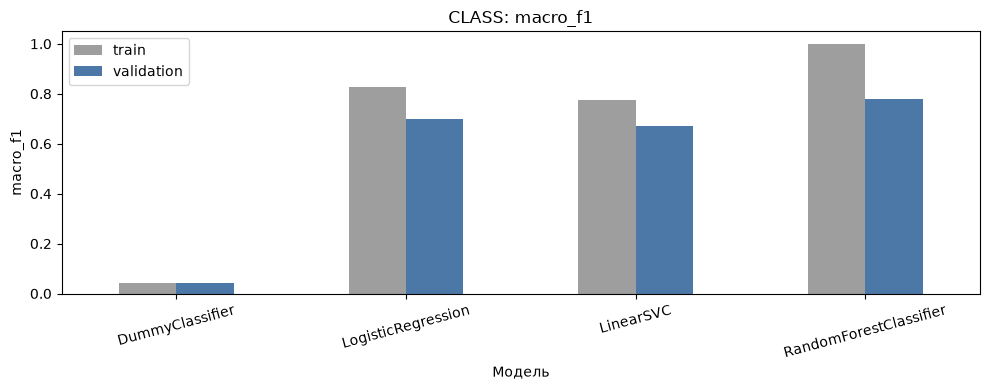

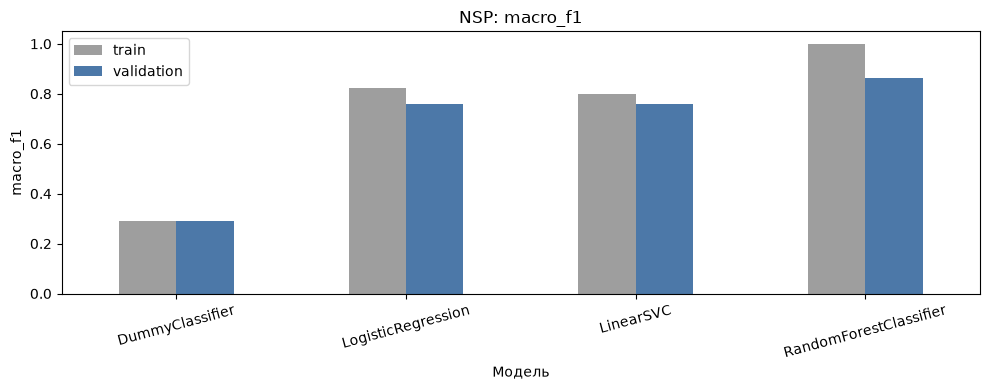

In [10]:
comparison_results = initial_results.copy()
comparison_results["f1_gap"] = comparison_results["train_macro_f1"] - comparison_results["validation_macro_f1"]
for target in ClassificationTarget:
    print(f"Цель: {target.value}")
    display(comparison_results.loc[comparison_results["Цель"].eq(target.value)]
            .sort_values("validation_macro_f1", ascending=False).round(4))
import matplotlib.pyplot as plt

for target in ClassificationTarget:
    results = comparison_results.loc[comparison_results["Цель"].eq(target.value)].set_index("Модель")
    for metric in ["macro_f1"]:
        ax = results[[f"train_{metric}", f"validation_{metric}"]].rename(
            columns={f"train_{metric}": "train", f"validation_{metric}": "validation"},
        ).plot.bar(figsize=(10, 4), color=["#9e9e9e", "#4c78a8"], rot=15)
        ax.set_title(f"{target.value}: {metric}")
        ax.set_ylim(0, 1.05)
        ax.set_ylabel(metric)
        ax.figure.tight_layout()
        plt.show()


### Качество по отдельным классам

Для каждой цели построим отдельные столбчатые диаграммы precision, recall и F1. По горизонтали — категории, цвет обозначает модель; по вертикали — значение метрики от 0 до 1.

Под категорией указано n — support, то есть число записей этой категории в validation. Это объём данных для оценки, а не показатель качества модели. Например, при n=14 один дополнительный найденный случай меняет recall примерно на 0,071, а при n=328 — только на 0,003. Поэтому оценки редких категорий менее устойчивы.

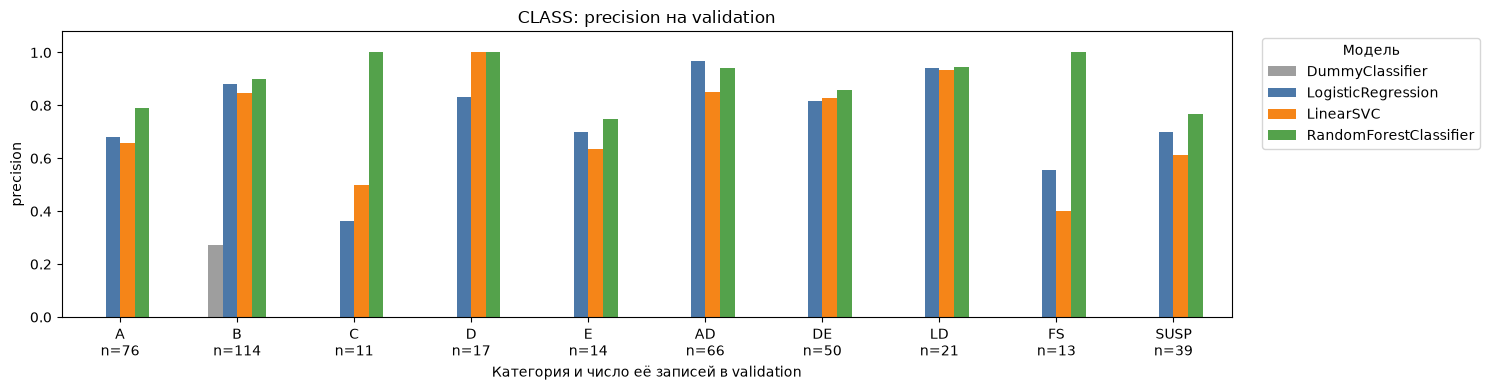

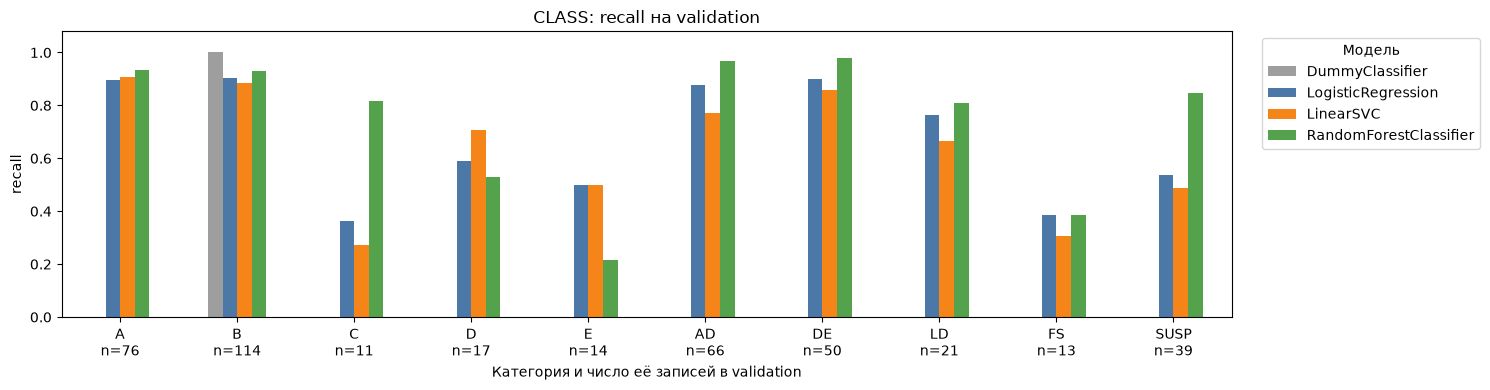

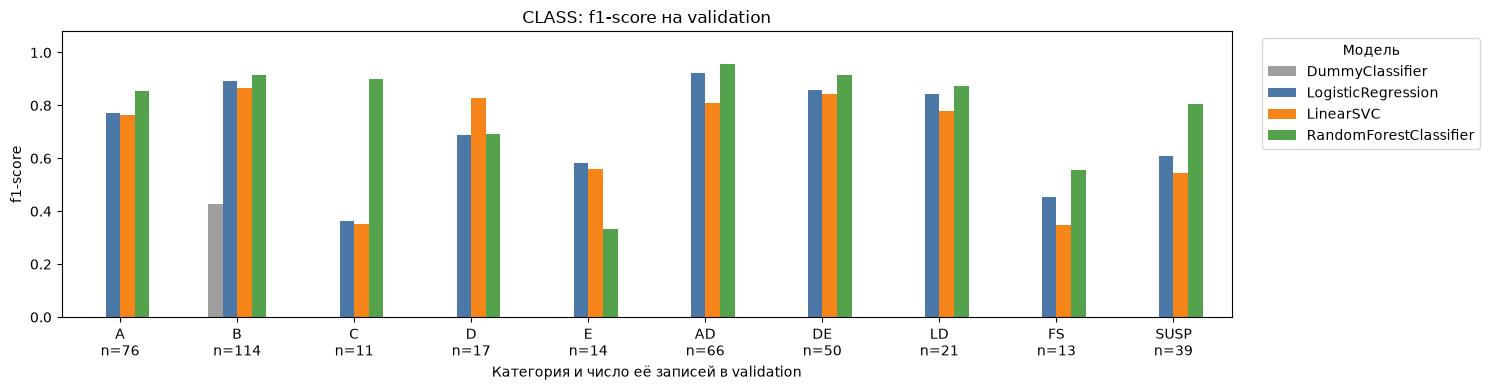

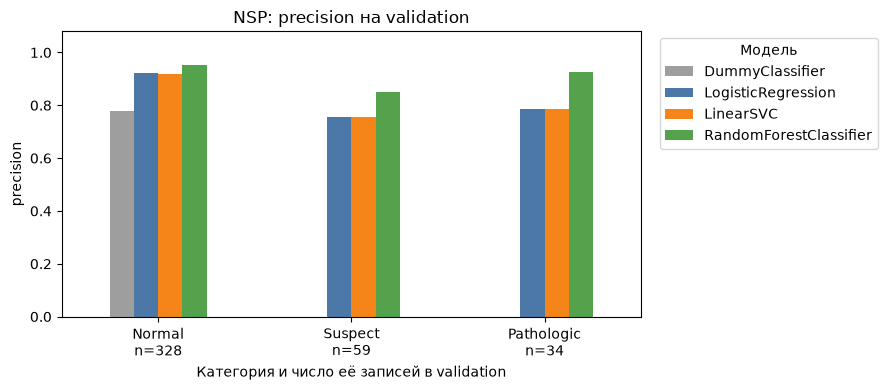

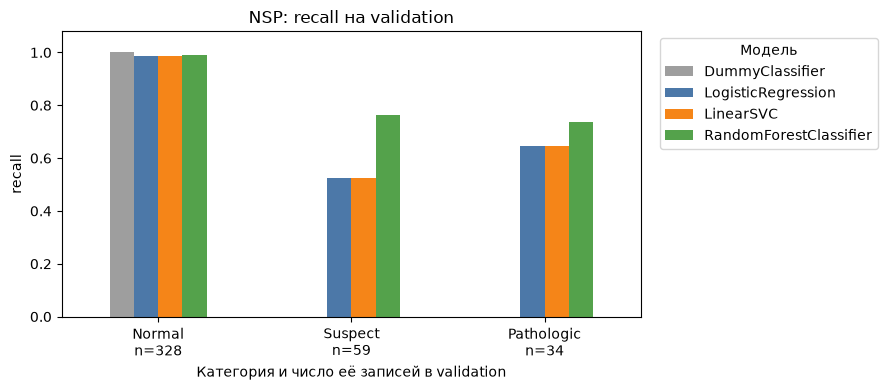

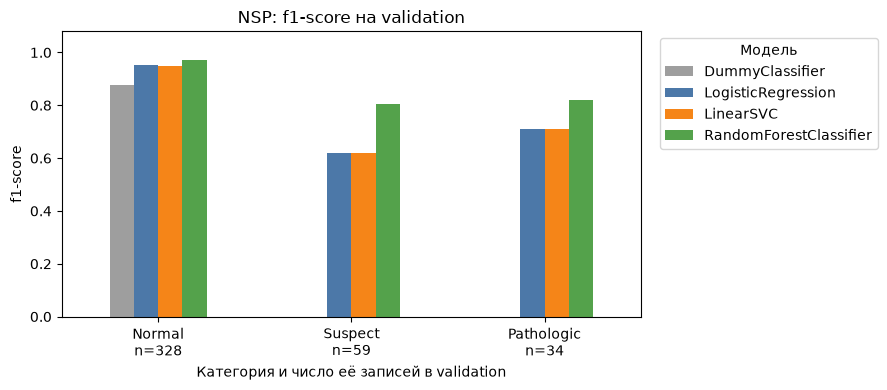

In [11]:
import matplotlib.pyplot as plt

model_colors = ["#9e9e9e", "#4c78a8", "#f58518", "#54a24b"]
for target in ClassificationTarget:
    rows = []
    for (model_target, model_name), evaluations in model_evaluations.items():
        if model_target != target:
            continue
        evaluation = evaluations["validation"]
        for label in evaluation.labels:
            rows.append({"Модель": model_name, "Категория": label, **evaluation.report[label]})
    report = pd.DataFrame(rows)
    labels = {ClassificationTarget.CLASS: class_mapping, ClassificationTarget.NSP: nsp_mapping}[target].values()
    support = report.groupby("Категория")["support"].first()
    for metric in ["precision", "recall", "f1-score"]:
        values = report.pivot(index="Категория", columns="Модель", values=metric).reindex(labels)
        values = values.reindex(columns=["DummyClassifier", "LogisticRegression", "LinearSVC", "RandomForestClassifier"])
        ax = values.plot.bar(figsize=(15 if target == ClassificationTarget.CLASS else 9, 4), color=model_colors)
        ax.set_ylim(0, 1.08)
        ax.set_title(f"{target.value}: {metric} на validation")
        ax.set_ylabel(metric)
        ax.set_xlabel("Категория и число её записей в validation")
        ax.set_xticklabels([f"{label}\nn={int(support[label])}" for label in values.index], rotation=0)
        ax.legend(title="Модель", bbox_to_anchor=(1.02, 1), loc="upper left")
        ax.figure.tight_layout()
        plt.show()

### Матрицы ошибок

Строки — истинные категории, столбцы — предсказанные. Числа на диагонали — правильные ответы; остальные — ошибки. Построим по четыре матрицы для каждой цели, включая DummyClassifier, чтобы увидеть, какие категории модели пропускают и с чем путают.

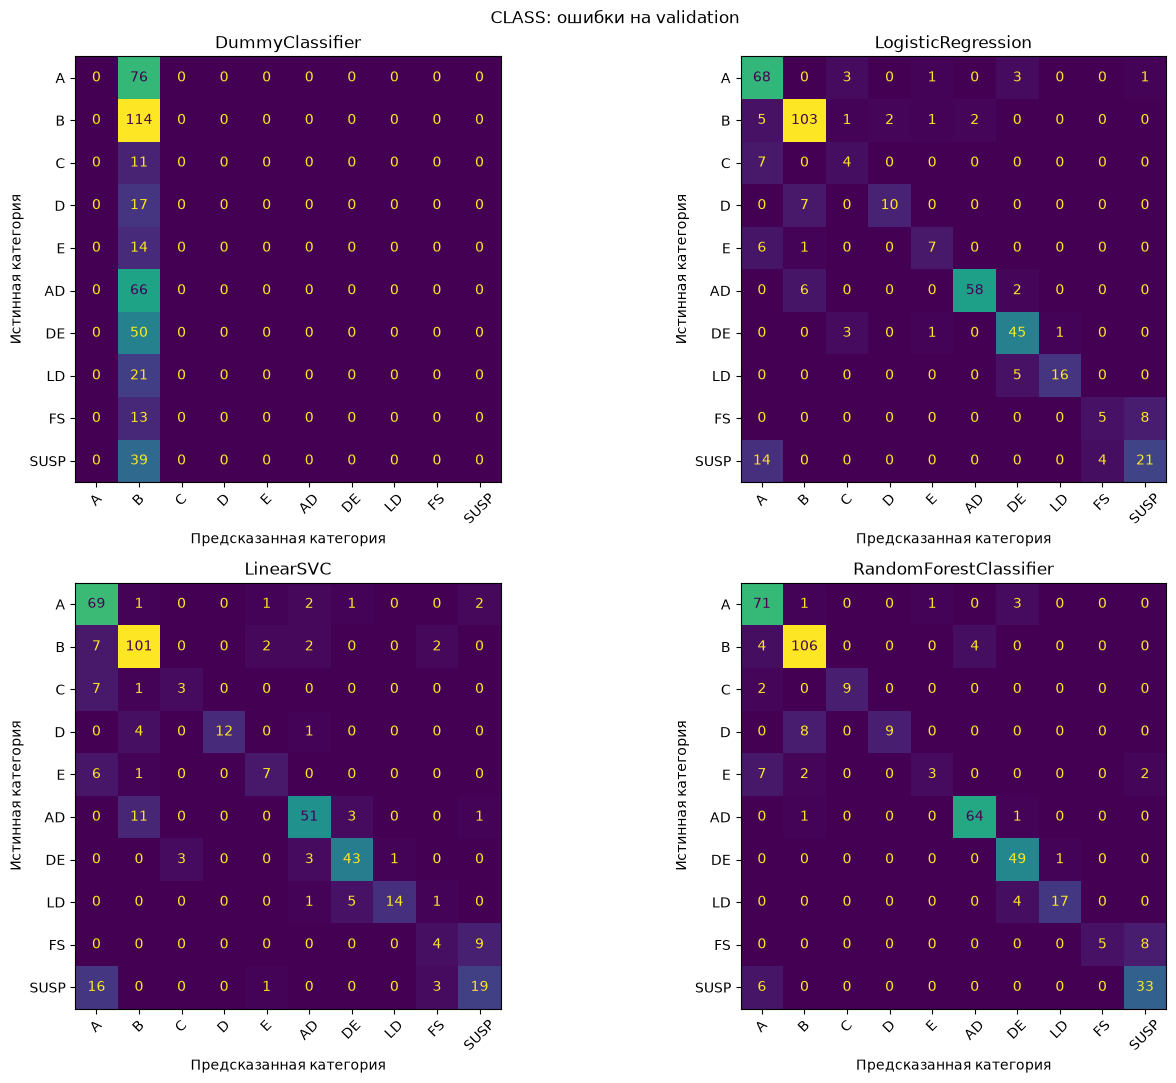

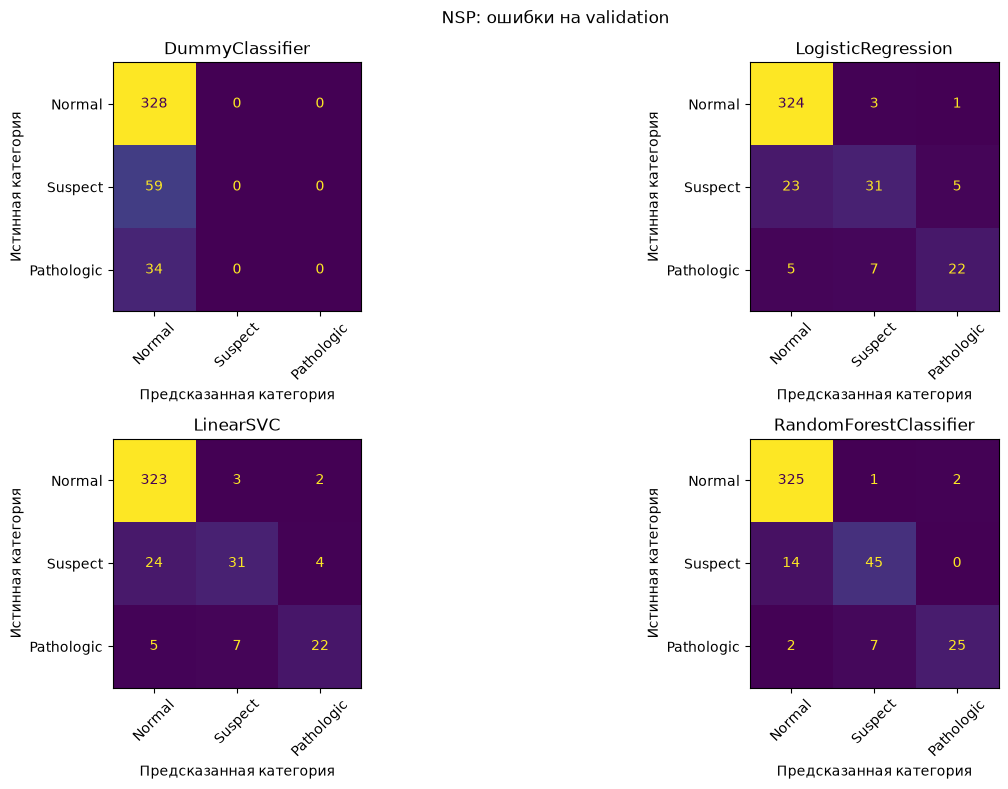

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for target in ClassificationTarget:
    fig, axes = plt.subplots(2, 2, figsize=(14, 11 if target == ClassificationTarget.CLASS else 8))
    target_models = [(name, evaluations["validation"])
                     for (model_target, name), evaluations in model_evaluations.items() if model_target == target]
    for ax, (model_name, evaluation) in zip(axes.flat, target_models):
        ConfusionMatrixDisplay(
            confusion_matrix=pd.DataFrame(evaluation.confusion).to_numpy(), display_labels=evaluation.labels,
        ).plot(ax=ax, colorbar=False, xticks_rotation=45)
        ax.set_title(model_name)
        ax.set_xlabel("Предсказанная категория")
        ax.set_ylabel("Истинная категория")
    fig.suptitle(f"{target.value}: ошибки на validation")
    fig.tight_layout()
    plt.show()

### Ошибки, важные для сценария приоритизации

В учебном сервисе подозрительные и патологические записи должны получать повышенный приоритет. 
- Pathologic → Normal — наиболее нежелательная ошибка: патологическая запись не получает предупреждения.
- Suspect → Normal также лишает запись повышенного приоритета.
- Pathologic → Suspect сохраняет предупреждение, но занижает категорию состояния.
- Normal → Suspect/Pathologic создаёт лишнее предупреждение и увеличивает объём проверки.

Это приоритеты выбранного сценария, а не установленная клиническая оценка тяжести ошибок.

In [13]:
nsp_error_rows = []
for (target, model_name), evaluations in model_evaluations.items():
    if target != ClassificationTarget.NSP or model_name == "DummyClassifier":
        continue
    matrix = evaluations["validation"].confusion
    nsp_error_rows.append({
        "Модель": model_name,
        "Pathologic → Normal": matrix[2][0],
        "Pathologic → Suspect": matrix[2][1],
        "Suspect → Normal": matrix[1][0],
        "Normal → Suspect/Pathologic": matrix[0][1] + matrix[0][2],
    })
nsp_error_report = pd.DataFrame(nsp_error_rows)
display(nsp_error_report.set_index("Модель"))

,Pathologic → Normal,Pathologic → Suspect,Suspect → Normal,Normal → Suspect/Pathologic
Модель,,,,
LogisticRegression,5,7,23,4
LinearSVC,5,7,24,5
RandomForestClassifier,2,7,14,3


### Выводы по сравнению моделей

**1. Общее качество на validation**

| Модель | CLASS: macro-F1 | CLASS: weighted-F1 | CLASS: accuracy | NSP: macro-F1 | NSP: weighted-F1 | NSP: accuracy |
|---|---:|---:|---:|---:|---:|---:|
| DummyClassifier | 0,043 | 0,115 | 0,271 | 0,292 | 0,682 | 0,779 |
| LogisticRegression | 0,698 | 0,796 | 0,800 | 0,761 | 0,887 | 0,895 |
| LinearSVC | 0,669 | 0,761 | 0,767 | 0,760 | 0,884 | 0,893 |
| RandomForest | 0,780 | 0,858 | 0,869 | 0,865 | 0,936 | 0,938 |

RandomForest лидирует по macro-F1 для обеих целей. Это результат исходных настроек; окончательный выбор выполняется после подбора параметров.

RandomForest лидирует также по weighted-F1 для обеих целей. Weighted-F1 учитывает частоту классов: хорошие результаты на распространённых категориях влияют на него сильнее. Поэтому его рассматриваем вместе с macro-F1 и recall редких классов, чтобы не скрыть пропуски подозрительных и патологических записей.

**2. Переобучение и настройки сложности**

- У RandomForest train_macro_f1 = 1 означает отсутствие ошибок на обучающих записях. Этот результат описывает подгонку к train, а качество на других исследованиях показывает validation.
- Лес получил macro-F1 0,780 и 0,865 на validation вместо 1 на train. Он способен точно воспроизводить обучающие ответы, но часть закономерностей не переносится на новые исследования. Это признак переобучения. Практическая проблема — пропущенные и неправильно классифицированные записи; их количество видно в матрицах ошибок.
- Переобучение не делает лес автоматически худшей моделью: на validation он превосходит линейные модели. Проверим, улучшит ли ограничение сложности именно validation, а не только уменьшит разрыв с train.
- Неограниченная глубина выбрана потому, что для исходного запуска использовано стандартное max_depth=None. min_samples_leaf=1 допускает листья с одной записью. Оптимальными эти настройки пока не считаются.
- LogisticRegression и LinearSVC имеют линейные границы классов и исходное C=1, определяющее силу регуляризации. Их результат тоже может улучшиться после настройки. Ограничения разных семейств моделей нельзя уравнять одним параметром глубины; сравнивать будем качество после небольшого подбора для каждого семейства.

**3. Паттерны CLASS, сложные для распознавания**

- **E:** лес находит 3 из 14 записей (recall 0,214), обе линейные модели — 7 из 14 (0,500). Здесь общий лидер хуже линейных моделей.
- **FS:** лес находит 5 из 13 (0,385), регрессия — также 5, LinearSVC — 4. Этот паттерн остаётся трудным для всех моделей.
- **D:** лес находит 9 из 17 (0,529), регрессия — 10 (0,588), LinearSVC — 12 (0,706). Это дополнительная причина сохранить LinearSVC среди кандидатов.
- **C:** лес находит 9 из 11 (0,818), регрессия — 4, LinearSVC — 3. Здесь преимущество леса заметно.
- Число validation-записей для этих паттернов невелико. Помимо macro-F1 при подборе проверим, не ухудшает ли выбранная настройка обнаружение редких категорий.

**4. Ошибки NSP и последствия для приоритизации**

- **Pathologic → Normal:** лес пропускает без предупреждения 2 из 34 патологических записей; каждая линейная модель — 5. Для выбранного сценария это наиболее нежелательная ошибка: запись не получает повышенного приоритета.
- **Pathologic → Suspect:** у всех трёх моделей 7 случаев. Предупреждение сохраняется, но категория состояния занижена.
- **Suspect → Normal:** лес пропускает 14 из 59 подозрительных записей, регрессия — 23, LinearSVC — 24. Такие записи также теряют повышенный приоритет.
- **Normal → Suspect/Pathologic:** лес создаёт 3 лишних предупреждения, регрессия — 4, LinearSVC — 5. Это увеличивает объём ручной проверки.
- Лес правильно определяет Pathologic в 25 из 34 случаев (recall 0,735); 25 из 27 его предсказаний Pathologic верны (precision 0,926). Он снижает число наиболее нежелательных ошибок относительно линейных моделей, но не устраняет их. При подборе учитываем и macro-F1, и пропуски Pathologic/Suspect.

**5. Модели для подбора параметров**

- Для обеих целей проверяем RandomForest, LogisticRegression и LinearSVC. Исключать LinearSVC по исходным настройкам преждевременно: для NSP его macro-F1 почти совпадает с регрессией, а для CLASS он лучше определяет D.
- У RandomForest подбираем число деревьев, ограничения сложности, max_features и class_weight. У линейных моделей — C, class_weight, fit_intercept и tol; дополнительно solver у LogisticRegression и loss у LinearSVC. Диапазоны и бюджет поиска задаём в пункте 6.
- CLASS и NSP настраиваются независимо. Сейчас лес лидирует для обеих целей, но итоговые семейства моделей и параметры могут различаться.
- Все модели сравниваются на одних train/validation; решение принимается по validation с учётом ошибок отдельных классов. Test остаётся для итоговой оценки.

## 6. Подбор параметров

Исходный RandomForest используем как baseline для CLASS и NSP: он показал лучшие macro-F1 и weighted-F1 на validation. Его модель, параметры и результаты сохраняем без изменений.

### 6.1. Условия поиска и выбор модели

Используем Optuna с TPE по аналогии с coffee_ml_pipeline. Функция objective обучает Pipeline на train и возвращает macro-F1 на validation. TPE использует результаты предыдущих попыток для выбора следующей комбинации. Seed фиксирован; попытки выполняются последовательно.

Для каждой из трёх моделей и каждой цели выполняем settings.optuna_budget_stage_1 попыток. Затем для победителя каждой цели выполняем settings.optuna_budget_stage_2 дополнительных попыток. Бюджеты задаются в ExperimentSettings.

Выбираем максимальный macro-F1; при равенстве — weighted-F1. Weighted-F1 и accuracy могут снизиться относительно baseline не более чем на 0,01. Для NSP число Pathologic → Normal и Suspect → Normal не должно увеличиваться. После завершения поиска проверяем эти условия по validation и выбираем модель вручную, описывая решение в выводах. Optuna ищет максимум macro-F1 без дополнительных ограничений внутри TPE. Baseline остаётся среди кандидатов: если поиск не даёт допустимого улучшения, сохраняем исходную модель.

Test не используется при поиске. Не объединяем train и validation для финального обучения: это сохраняет одинаковые условия сравнения с baseline.



### Подготовка поиска

Фиксируем baseline и создаём списки результатов. Используем обычные таблицы и словари; дополнительные классы и функции для подбора не нужны.

parameter_spaces задаёт для каждой модели тип подбора и диапазон каждого параметра: categorical — выбор из списка, int — целые значения, float — вещественные. В objective выбираем соответствующий метод trial.suggest_* по этому маппингу.


In [14]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

baseline_evaluations = {
    ClassificationTarget.CLASS: model_evaluations[(ClassificationTarget.CLASS, "RandomForestClassifier")]["validation"],
    ClassificationTarget.NSP: model_evaluations[(ClassificationTarget.NSP, "RandomForestClassifier")]["validation"],
}
baseline_run_ids = {
    ClassificationTarget.CLASS: run_ids[(ClassificationTarget.CLASS, "RandomForestClassifier")],
    ClassificationTarget.NSP: run_ids[(ClassificationTarget.NSP, "RandomForestClassifier")],
}
search_runs = {}
trial_run_ids = {}
first_stage_rows = []

parameter_spaces = {'RandomForestClassifier': {'n_estimators': ('int', {'low': 100, 'high': 400, 'step': 50}),
                            'max_depth': ('categorical', {'choices': [None, 4, 8, 12, 20, 30]}),
                            'min_samples_split': ('int', {'low': 2, 'high': 12}),
                            'min_samples_leaf': ('int', {'low': 1, 'high': 10}),
                            'max_features': ('categorical', {'choices': ['sqrt', 'log2', 0.5, 1.0]}),
                            'class_weight': ('categorical', {'choices': [None, 'balanced']})},
 'LogisticRegression': {'C': ('float', {'low': 0.001, 'high': 100.0, 'log': True}),
                        'class_weight': ('categorical', {'choices': [None, 'balanced']}),
                        'solver': ('categorical', {'choices': ['lbfgs', 'newton-cg']}),
                        'fit_intercept': ('categorical', {'choices': [True, False]}),
                        'tol': ('float', {'low': 1e-06, 'high': 0.001, 'log': True})},
 'LinearSVC': {'C': ('float', {'low': 0.001, 'high': 100.0, 'log': True}),
               'class_weight': ('categorical', {'choices': [None, 'balanced']}),
               'loss': ('categorical', {'choices': ['hinge', 'squared_hinge']}),
               'fit_intercept': ('categorical', {'choices': [True, False]}),
               'tol': ('float', {'low': 1e-06, 'high': 0.001, 'log': True})}}


### 6.2. Расширенный подбор для трёх моделей

Диапазоны заданы в parameter_spaces. Для каждой модели и цели выполняем settings.optuna_budget_stage_1 попыток.

| Модель | Подбираемые параметры | Что проверяем |
|---|---|---|
| RandomForest | n_estimators, max_depth, min_samples_split, min_samples_leaf, max_features, class_weight | Число деревьев, сложность деревьев, разнообразие признаков и веса классов |
| LogisticRegression | C, class_weight, solver, fit_intercept, tol | Регуляризацию, веса классов, способ решения, свободный член и точность сходимости |
| LinearSVC | C, class_weight, loss, fit_intercept, tol | Регуляризацию, веса классов, функцию потерь, свободный член и точность сходимости |

Для LinearSVC loss=hinge требует dual=True; при squared_hinge используем dual="auto". Поэтому dual задаётся совместимо с выбранной функцией потерь. max_iter=20000 оставляем фиксированным ограничением итераций. tol и solver влияют на решение задачи оптимизации; их подбор не гарантирует улучшения качества.

В таблице покажем лучший macro-F1 каждого семейства и соответствующие weighted-F1 и accuracy вместе с baseline. Выбор и проверка условий выполняются вручную по validation.


In [15]:
for target in ClassificationTarget:
    for model_name in classifiers:
        def objective(trial):
            suggest = {
                "categorical": trial.suggest_categorical,
                "int": trial.suggest_int,
                "float": trial.suggest_float,
            }
            params = {name: suggest[kind](name, **options) for name, (kind, options) in parameter_spaces[model_name].items()}
            if model_name == "LinearSVC":
                params["dual"] = True if params["loss"] == "hinge" else "auto"
                params["max_iter"] = 20000
            model = Pipeline(
                [("scaler", StandardScaler()), ("classifier", clone(classifiers[model_name]).set_params(**params))]
            )
            model, evaluations, run_id = train_and_log_classifier(
                model, target, f"{target.value}_{model_name}_stage_1_{trial.number}", save_model=False,
            )
            trial_run_ids[(target, model_name, "stage_1", trial.number)] = run_id
            search_runs[run_id] = {"model": model, "evaluations": evaluations, "params": params}
            evaluation = evaluations["validation"]
            first_stage_rows.append({
                "Цель": target.value, "Модель": model_name, "run_id": run_id,
                **{metric: evaluation.metrics[metric] for metric in ["macro_f1", "weighted_f1", "accuracy"]},
            })
            return evaluation.metrics["macro_f1"]

        sampler = optuna.samplers.TPESampler(seed=settings.random_state)
        study = optuna.create_study(direction="maximize", sampler=sampler)
        study.optimize(objective, n_trials=settings.optuna_budget_stage_1)


🏃 View run CLASS_LogisticRegression_stage_1_0 at: http://127.0.0.1:5001/#/experiments/1/runs/e469fb0551c443248d3d84a6f6e86c5a
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LogisticRegression_stage_1_1 at: http://127.0.0.1:5001/#/experiments/1/runs/7045a1efee824a6092c817f352770b8d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LogisticRegression_stage_1_2 at: http://127.0.0.1:5001/#/experiments/1/runs/3b00625fba9c472ea0ad20675bedb212
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LogisticRegression_stage_1_3 at: http://127.0.0.1:5001/#/experiments/1/runs/04055de7ba614a8b847f1e7fca7ccaef
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LogisticRegression_stage_1_4 at: http://127.0.0.1:5001/#/experiments/1/runs/b0c4e09746ae404a934529ee0dc4160a
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LogisticRegression_stage_1_5 at: http://127.0.0.1:500

/Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


🏃 View run CLASS_LinearSVC_stage_1_1 at: http://127.0.0.1:5001/#/experiments/1/runs/163be20df67d47a99f4a58b4aa842d02
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_2 at: http://127.0.0.1:5001/#/experiments/1/runs/610bb5d38dda405198238248b3532321
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_3 at: http://127.0.0.1:5001/#/experiments/1/runs/2ba2047918bc4254aa1db149510fab49
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_4 at: http://127.0.0.1:5001/#/experiments/1/runs/5348bdd877744772a6d31bca0c74bfdf
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_5 at: http://127.0.0.1:5001/#/experiments/1/runs/ef54380251754fce8213e335d5fbb34c
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_6 at: http://127.0.0.1:5001/#/experiments/1/runs/e72f9e3f4bd04e0b85aad0ccccf2e44

/Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


🏃 View run CLASS_LinearSVC_stage_1_16 at: http://127.0.0.1:5001/#/experiments/1/runs/9b1ed9e7a39c4aa583ba0226a8358d6e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_17 at: http://127.0.0.1:5001/#/experiments/1/runs/0b720a86404e4b3bab43f145e6f10cf1
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_18 at: http://127.0.0.1:5001/#/experiments/1/runs/e0275d2cab91436f8de46f6c01f9ef28
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_19 at: http://127.0.0.1:5001/#/experiments/1/runs/96d629776a09434dac946d9146df1c28
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_20 at: http://127.0.0.1:5001/#/experiments/1/runs/662ee608115b48faa394185ddf9d52a2
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_LinearSVC_stage_1_21 at: http://127.0.0.1:5001/#/experiments/1/runs/9ad0667b7971454d8d94983f8

/Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


🏃 View run NSP_LinearSVC_stage_1_1 at: http://127.0.0.1:5001/#/experiments/1/runs/b080ae5d9ad740ccb2ca7f159d782d7f
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_LinearSVC_stage_1_2 at: http://127.0.0.1:5001/#/experiments/1/runs/21a6c6a9dc804ef0bcaaa692ea95ff4e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_LinearSVC_stage_1_3 at: http://127.0.0.1:5001/#/experiments/1/runs/54759fc7f42b4a4997293ccd05da6142
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_LinearSVC_stage_1_4 at: http://127.0.0.1:5001/#/experiments/1/runs/ebb8334e28644ce1bf1822fe691c8144
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_LinearSVC_stage_1_5 at: http://127.0.0.1:5001/#/experiments/1/runs/ef12635662884a068eb366e2b3cfff9f
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_LinearSVC_stage_1_6 at: http://127.0.0.1:5001/#/experiments/1/runs/2385889bdd834fabb04046c42175f818
🧪 View exp

/Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


🏃 View run NSP_LinearSVC_stage_1_24 at: http://127.0.0.1:5001/#/experiments/1/runs/ec994130ed304ceba4b18bd6f4e65cf5
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_1_0 at: http://127.0.0.1:5001/#/experiments/1/runs/f94d2845aa134ae7928a72a1c7755708
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_1_1 at: http://127.0.0.1:5001/#/experiments/1/runs/b9d65ea1447e43eeb0f381a9694d7bd5
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_1_2 at: http://127.0.0.1:5001/#/experiments/1/runs/b020f37c99c04c5e9cfcaf916dddc299
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_1_3 at: http://127.0.0.1:5001/#/experiments/1/runs/b00f727fd0724eb1a0803bbaa8ae2b66
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_1_4 at: http://127.0.0.1:500

### Результаты первого подбора

Для каждой модели и цели покажем попытку с максимальным macro-F1. CLASS и NSP расположим рядом. Это результаты оптимизации; решение о выборе модели и проверку условий описываем в выводах. Baseline добавлен для сравнения.


In [16]:
first_stage_results = pd.DataFrame(first_stage_rows)
best_results = first_stage_results.sort_values("macro_f1", ascending=False).drop_duplicates(["Модель", "Цель"])
baseline_rows = pd.DataFrame([
    {"Модель": "Baseline (RandomForest)", "Цель": "CLASS", **baseline_evaluations[ClassificationTarget.CLASS].metrics},
    {"Модель": "Baseline (RandomForest)", "Цель": "NSP", **baseline_evaluations[ClassificationTarget.NSP].metrics},
])
best_results = pd.concat([baseline_rows, best_results])
first_stage_table = best_results.pivot(index="Модель", columns="Цель", values=["macro_f1", "weighted_f1", "accuracy"])
first_stage_table = first_stage_table.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
first_stage_table.columns = [f"{target}: {metric}" for target, metric in first_stage_table.columns]
display(first_stage_table.round(4))


,CLASS: macro_f1,CLASS: weighted_f1,CLASS: accuracy,NSP: macro_f1,NSP: weighted_f1,NSP: accuracy
Модель,,,,,,
Baseline (RandomForest),0.7798,0.8581,0.8694,0.8649,0.9358,0.9382
LinearSVC,0.7620,0.8065,0.8052,0.8113,0.9088,0.9074
LogisticRegression,0.7647,0.8200,0.8171,0.8499,0.9137,0.9074
RandomForestClassifier,0.8641,0.9019,0.9050,0.8895,0.9469,0.9477


### Выводы после первого подбора

**1. Общее качество.** Для обеих целей выбираем RandomForest: он превосходит baseline и линейные модели по macro-F1 и выполняет согласованные условия по дополнительным метрикам и пропускам NSP. В этом поиске линейные модели не выполнили все условия относительно baseline.

| Цель | Macro-F1 baseline | После подбора | Weighted-F1 после подбора | Accuracy после подбора |
|---|---:|---:|---:|---:|
| CLASS | 0,780 | 0,864 | 0,902 | 0,905 |
| NSP | 0,865 | 0,890 | 0,947 | 0,948 |

**2. Параметры.** 
- Для CLASS выбраны 100 деревьев, max_depth=12, min_samples_split=6, min_samples_leaf=1, max_features=0.5 и class_weight="balanced".
- Для NSP — 350 деревьев, max_depth=20, min_samples_split=2, min_samples_leaf=1, max_features="sqrt" и class_weight="balanced".
  
Изменилось несколько параметров одновременно, поэтому нельзя приписать улучшение только весам классов.

**3. Ошибки NSP на validation.** Pathologic → Normal: 2 → 2; Suspect → Normal: 14 → 9. Выбранная модель снизила пропуски Suspect без увеличения пропусков Pathologic.

**4. Трудные паттерны CLASS.** Recall baseline → выбранный вариант:
- E: 0.214 → 0.429.
- FS: 0.385 → 0.692.
- D: 0.529 → 0.824.
- C: 0.818 → 0.909.

**Выбор для уточнения.** CLASS — попытка №6; NSP — попытка №18. 


### 6.3. Уточнение RandomForest

Вновь подбираем все шесть параметров леса вокруг выбранных в предыдущем шаге значений.

Для CLASS проверяем 50–200 деревьев, глубины 8/12/16, min_samples_split=4–8, min_samples_leaf=1–3. Для NSP — 250–450 деревьев, глубины 16/20/24, min_samples_split=2–4, min_samples_leaf=1–3. Шаг числа деревьев — 50. Для max_features и class_weight сохраняем варианты первого этапа.

Выполняем settings.optuna_budget_stage_2 попыток для каждой цели. Первой попыткой повторяем выбранные параметры первого этапа. Результаты и ошибки оцениваем только на validation; затем фиксируем выбор перед проверкой на test.


In [17]:
first_stage_params = {
    ClassificationTarget.CLASS: {'n_estimators': 100, 'max_depth': 12, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': 'balanced'},
    ClassificationTarget.NSP: {'n_estimators': 350, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'},
}
refinement_spaces = {
    ClassificationTarget.CLASS: {
        "n_estimators": ("int", {"low": 50, "high": 200, "step": 50}),
        "max_depth": ("categorical", {"choices": [8, 12, 16]}),
        "min_samples_split": ("int", {"low": 4, "high": 8}),
        "min_samples_leaf": ("int", {"low": 1, "high": 3}),
        "max_features": ("categorical", {"choices": ["sqrt", "log2", 0.5, 1.0]}),
        "class_weight": ("categorical", {"choices": [None, "balanced"]}),
    },
    ClassificationTarget.NSP: {
        "n_estimators": ("int", {"low": 250, "high": 450, "step": 50}),
        "max_depth": ("categorical", {"choices": [16, 20, 24]}),
        "min_samples_split": ("int", {"low": 2, "high": 4}),
        "min_samples_leaf": ("int", {"low": 1, "high": 3}),
        "max_features": ("categorical", {"choices": ["sqrt", "log2", 0.5, 1.0]}),
        "class_weight": ("categorical", {"choices": [None, "balanced"]}),
    },
}
for target in ClassificationTarget:
    def objective(trial):
        suggest = {"categorical": trial.suggest_categorical, "int": trial.suggest_int, "float": trial.suggest_float}
        params = {name: suggest[kind](name, **options)
                  for name, (kind, options) in refinement_spaces[target].items()}
        model = Pipeline([("scaler", StandardScaler()),
                          ("classifier", clone(classifiers["RandomForestClassifier"]).set_params(**params))])
        model, evaluations, run_id = train_and_log_classifier(
            model, target, f"{target.value}_RandomForestClassifier_stage_2_{trial.number}", save_model=False,
        )
        trial_run_ids[(target, "RandomForestClassifier", "stage_2", trial.number)] = run_id
        search_runs[run_id] = {"model": model, "evaluations": evaluations, "params": params}
        evaluation = evaluations["validation"]
        return evaluation.metrics["macro_f1"]

    sampler = optuna.samplers.TPESampler(seed=settings.random_state)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.enqueue_trial(first_stage_params[target])
    study.optimize(objective, n_trials=settings.optuna_budget_stage_2)


🏃 View run CLASS_RandomForestClassifier_stage_2_0 at: http://127.0.0.1:5001/#/experiments/1/runs/210f19c68a964559a78f74040ce5192d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_1 at: http://127.0.0.1:5001/#/experiments/1/runs/ed348c02fcc540d3bfd29c6cd7947266
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_2 at: http://127.0.0.1:5001/#/experiments/1/runs/6e2bdb6eb4a3456383607befbd03c963
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_3 at: http://127.0.0.1:5001/#/experiments/1/runs/4bc5b28e4b88458eb5896802c88291c1
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_4 at: http://127.0.0.1:5001/#/experiments/1/runs/7c1bedf1ef6442b685c1e7cf5eb8cc82
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_5 

### Сохранение выбранных моделей в MLflow

По validation вручную выбраны варианты второго этапа: CLASS — попытка №13; NSP — попытка №34. Номера и параметры фиксируем перед проверкой test. В выбранных запусках сохраняем Pipeline и параметры, без повторного обучения.


In [18]:
first_stage_run_ids = {
    ClassificationTarget.CLASS: trial_run_ids[(ClassificationTarget.CLASS, "RandomForestClassifier", "stage_1", 6)],
    ClassificationTarget.NSP: trial_run_ids[(ClassificationTarget.NSP, "RandomForestClassifier", "stage_1", 18)],
}
selected_run_ids = {
    ClassificationTarget.CLASS: trial_run_ids[(ClassificationTarget.CLASS, "RandomForestClassifier", "stage_2", 13)],
    ClassificationTarget.NSP: trial_run_ids[(ClassificationTarget.NSP, "RandomForestClassifier", "stage_2", 34)],
}
selected_models = {
    ClassificationTarget.CLASS: search_runs[selected_run_ids[ClassificationTarget.CLASS]]["model"],
    ClassificationTarget.NSP: search_runs[selected_run_ids[ClassificationTarget.NSP]]["model"],
}
for target, model in selected_models.items():
    with mlflow.start_run(run_id=selected_run_ids[target]):
        mlflow.set_tag("role", "selected_classical")
        mlflow.sklearn.log_model(model, name="model", input_example=X_train.head(5),
            serialization_format="cloudpickle", pip_requirements=model_requirements)
        mlflow.log_dict(search_runs[selected_run_ids[target]]["params"], "selected_params.json")


🏃 View run CLASS_RandomForestClassifier_stage_2_13 at: http://127.0.0.1:5001/#/experiments/1/runs/526149c099c046e0b6ed14b43e2b928d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_2_34 at: http://127.0.0.1:5001/#/experiments/1/runs/0b5ffed9cd814b208e9369098002cf6a
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


### Сравнение этапов

Выведем уже рассчитанные validation-метрики baseline и вручную выбранных попыток. Здесь модели не обучаются и не выбираются.


In [19]:
stage_metrics = {
    ("CLASS", "baseline"): baseline_evaluations[ClassificationTarget.CLASS].metrics,
    ("CLASS", "stage_1"): search_runs[first_stage_run_ids[ClassificationTarget.CLASS]]["evaluations"]["validation"].metrics,
    ("CLASS", "selected"): search_runs[selected_run_ids[ClassificationTarget.CLASS]]["evaluations"]["validation"].metrics,
    ("NSP", "baseline"): baseline_evaluations[ClassificationTarget.NSP].metrics,
    ("NSP", "stage_1"): search_runs[first_stage_run_ids[ClassificationTarget.NSP]]["evaluations"]["validation"].metrics,
    ("NSP", "selected"): search_runs[selected_run_ids[ClassificationTarget.NSP]]["evaluations"]["validation"].metrics,
}
display(pd.DataFrame(stage_metrics).T[["macro_f1", "weighted_f1", "accuracy"]].round(4))


macro_f1  weighted_f1  accuracy
CLASS baseline    0.7798       0.8581    0.8694
      stage_1     0.8641       0.9019    0.9050
      selected    0.8642       0.8978    0.9002
NSP   baseline    0.8649       0.9358    0.9382
      stage_1     0.8895       0.9469    0.9477
      selected    0.8933       0.9494    0.9501

### Выводы после уточнения

**1. CLASS.** 
- Macro-F1 изменился с 0,864131 до 0,864232: рост всего на 0,000101.
- Weighted-F1 снизился с 0,901916 до 0,897818, accuracy — с 0,904988 до 0,900238;
- Относительно baseline согласованные условия выполнены. По правилу максимального macro-F1 выбран вариант второго этапа, но такое малое изменение не свидетельствует об устойчивом преимуществе над первым этапом. Параметры: {'n_estimators': 100, 'max_depth': 12, 'min_samples_split': 8, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': 'balanced'}.

**2. NSP.** 
- Macro-F1 вырос с 0,889542 до 0,893255.
- Weighted-F1 — с 0,946879 до 0,949383,
- accuracy — с 0,947743 до 0,950119.
- Suspect → Normal уменьшились с 9 до 8, Pathologic → Normal осталось 2. Параметры: {'n_estimators': 350, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2', 'class_weight': 'balanced'}.

**3. Выбор.** Для CLASS фиксируем попытку №13, для NSP — №34 второго этапа. Обе выбраны по validation; результаты test не использованы для выбора.


### 6.4. Оценка baseline и выбранных моделей на test

Baseline и модель после подбора оцениваем на всей тестовой выборке — 421 записи из test.csv. Для всех моделей используются одинаковые строки. Для CLASS и NSP используем те же входные признаки, но сравниваем предсказания с соответствующей целевой колонкой. Повторно не обучаем их и не меняем параметры по результатам проверки. Сохраняем test-метрики, отчёты и матрицы ошибок в соответствующие запуски MLflow.

Все значения в следующей таблице рассчитаны на test, а не на validation. Столбец macro_precision показывает среднюю precision по классам; macro_recall — средний recall по классам. Матрицы ошибок также построены на test. Таблица показывает общее качество; матрицы ошибок — конкретные перепутанные категории. Precision и recall усредняем по классам с одинаковым весом. Дополнительно сравниваем ошибки NSP, важные для приоритизации.


🏃 View run CLASS_RandomForestClassifier at: http://127.0.0.1:5001/#/experiments/1/runs/161891b000e34556a19d79067514c3de
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run CLASS_RandomForestClassifier_stage_2_13 at: http://127.0.0.1:5001/#/experiments/1/runs/526149c099c046e0b6ed14b43e2b928d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier at: http://127.0.0.1:5001/#/experiments/1/runs/b243c683ea374d6782f815ffdb3d960d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
🏃 View run NSP_RandomForestClassifier_stage_2_34 at: http://127.0.0.1:5001/#/experiments/1/runs/0b5ffed9cd814b208e9369098002cf6a
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


,Цель,Вариант,macro_f1,weighted_f1,accuracy,macro_precision,macro_recall
0,CLASS,baseline,0.7123,0.7986,0.8100,0.8603,0.6764
1,CLASS,selected,0.7773,0.8206,0.8195,0.7749,0.7896
2,NSP,baseline,0.8326,0.9117,0.9097,0.8464,0.8265
3,NSP,selected,0.8200,0.9018,0.8955,0.8050,0.8497


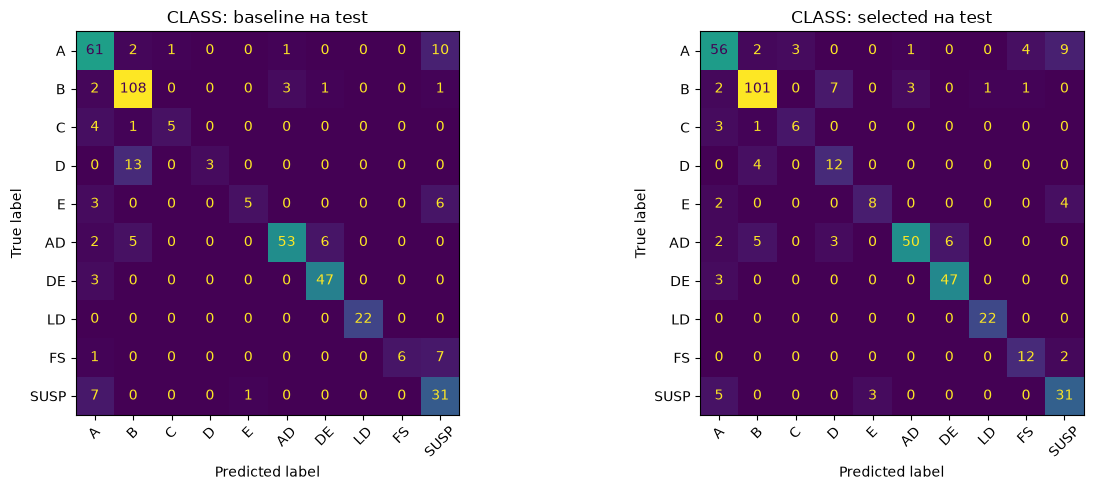

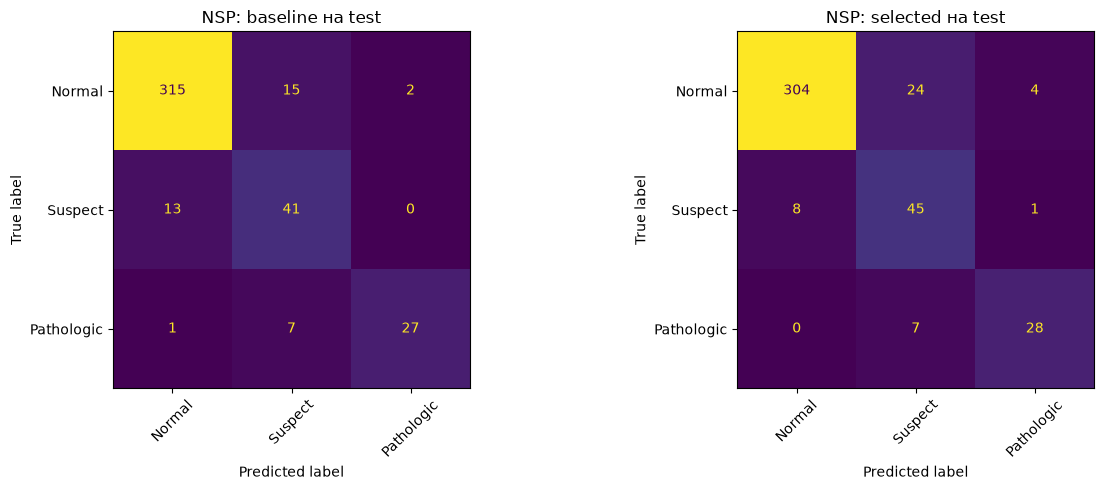

In [20]:
test_evaluations = {}
test_rows = []
for target in ClassificationTarget:
    for label, model, run_id in [
        ("baseline", trained_models[(target, "RandomForestClassifier")], baseline_run_ids[target]),
        ("selected", selected_models[target], selected_run_ids[target]),
    ]:
        evaluation = evaluate_classifier(test_df[target.value], model.predict(X_test), target)
        test_evaluations[(target, label)] = evaluation
        with mlflow.start_run(run_id=run_id):
            mlflow.log_metrics({f"test_{key}": value for key, value in evaluation.metrics.items()})
            mlflow.log_dict(evaluation.report, "test/classification_report.json")
            mlflow.log_dict({"labels": evaluation.labels, "matrix": evaluation.confusion},
                            "test/confusion_matrix.json")
        test_rows.append({
            "Цель": target.value, "Вариант": label,
            **{metric: evaluation.metrics[metric] for metric in ["macro_f1", "weighted_f1", "accuracy"]},
            "macro_precision": evaluation.report["macro avg"]["precision"],
            "macro_recall": evaluation.report["macro avg"]["recall"],
        })
display(pd.DataFrame(test_rows).round(4))
for target in ClassificationTarget:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, label in zip(axes, ["baseline", "selected"]):
        evaluation = test_evaluations[(target, label)]
        ConfusionMatrixDisplay(
            confusion_matrix=pd.DataFrame(evaluation.confusion).to_numpy(), display_labels=evaluation.labels,
        ).plot(ax=ax, colorbar=False, xticks_rotation=45)
        ax.set_title(f"{target.value}: {label} на test")
    fig.tight_layout()
    plt.show()


### Выводы по итоговой проверке

Test.csv содержит 421 запись: примерно 20% от 2108 подготовленных записей. Train содержит 1266 записей, validation — 421. Все test-записи использованы для сравнения; исследования в разных частях выборки не пересекаются.

| Цель | Вариант | Macro-F1 | Weighted-F1 | Accuracy |
|---|---|---:|---:|---:|
| CLASS | Baseline | 0,712 | 0,799 | 0,810 |
| CLASS | После подбора | 0,777 | 0,821 | 0,819 |
| NSP | Baseline | 0,833 | 0,912 | 0,910 |
| NSP | После подбора | 0,820 | 0,902 | 0,895 |

**1. CLASS — улучшение подтвердилось.**

- Macro-F1 вырос с 0,712340 до 0,777322 (+0,064982).
- Weighted-F1 вырос с 0,798601 до 0,820550, accuracy — с 0,809976 до 0,819477.
- Macro-recall вырос с 0,676358 до 0,789595, macro-precision снизился с 0,860265 до 0,774936. Модель обнаруживает больше записей разных категорий, но среди её предсказаний отдельных классов выросла доля ошибок.

**2. NSP — общие метрики снизились.**

- Macro-F1: 0,832569 → 0,819979 (−0,012590).
- Weighted-F1: 0,911656 → 0,901779 (−0,009876).
- Accuracy: 0,909739 → 0,895487 (−0,014252).
- Снижение accuracy больше 0,01. Улучшение общего качества NSP на test не фиксируется.

**3. Почему снизилось качество NSP на test.**

| Ошибка | Baseline | После подбора | Последствие для сервиса |
|---|---:|---:|---|
| Pathologic → Normal | 1 | 0 | Меньше патологических записей без предупреждения |
| Suspect → Normal | 13 | 8 | Меньше подозрительных записей без предупреждения |
| Pathologic → Suspect | 7 | 7 | Предупреждение сохраняется, но категория занижена |
| Normal → Suspect/Pathologic | 17 | 28 | Больше лишних предупреждений |

После подбора правильно определённых Normal стало на 11 меньше (315 → 304), Suspect — на 4 больше (41 → 45), Pathologic — на 1 больше (27 → 28). В сумме правильных ответов стало на 6 меньше: 383 → 377 из 421. Это объясняет снижение accuracy.

Модель чаще выдаёт предупреждение: пропуски уменьшаются, но ложных предупреждений становится больше. Для Suspect recall вырос с 0,759 до 0,833, а precision снизился с 0,651 до 0,592. Для Pathologic recall вырос с 0,771 до 0,800, а precision снизился с 0,931 до 0,848.

Снижение precision перевесило рост recall: F1 уменьшился для всех трёх категорий — Normal: 0,953 → 0,944; Suspect: 0,701 → 0,692; Pathologic: 0,844 → 0,824. Поэтому снизился и macro-F1. Меньше пропусков и выше F1 — разные результаты: первый важен для приоритизации, второй учитывает ещё и ложные предсказания.

**4. Почему улучшение validation не перенеслось на test.**

Optuna выбирала настройки по одному и тому же validation: 75 попыток первого этапа и 50 второго для каждой цели. Лучшие настройки могут подходить особенностям этих исследований и хуже работать на других. Test содержит другие исследования; высокий результат на validation не гарантирует такое же преимущество на test. Это возможная подстройка к validation при многократном подборе.

Установленный результат — увеличение ложных предупреждений на test. Подстройка к validation — возможное объяснение, а не доказанная единственная причина. Одновременно изменились несколько параметров леса, поэтому приписывать ухудшение только class_weight="balanced" или глубине деревьев нельзя.

**5. Какие модели берём в итоге.**

- **CLASS — оптимизированный RandomForest, попытка №13 второго этапа.** Улучшение macro-F1, weighted-F1 и accuracy подтвердилось на test.
- **NSP — оптимизированный RandomForest, попытка №34 второго этапа.** В сценарии приоритизации ложное предупреждение менее вредно, чем отсутствие предупреждения для Suspect или Pathologic. Принимаем 11 дополнительных ложных предупреждений ради уменьшения пропусков: Pathologic → Normal — на 1, Suspect → Normal — на 5. Это выбор в пользу обнаружения подозрительных записей, несмотря на снижение общих метрик.

Обе модели были выбраны по validation до проверки test и выполнили ограничения на этой выборке. По результатам test выбор сохраняем с учётом приоритетов сервиса. Baseline остаётся ориентиром для сравнения; для NSP не называем оптимизированный вариант лучшим по всем показателям. Выбранные параметры больше не меняем по test.

**6. Ограничения.** Сравнение выполнено на одном групповом разбиении; устойчивость преимущества не проверена на других разбиениях. Test уже просмотрен и использован при обсуждении итогового решения, поэтому повторные изменения моделей по его результатам потребуют новой независимой проверки.


## 7. Экспорт выбранных моделей

Сохраняем два оптимизированных Pipeline в runtime/models/classical/: для CLASS — попытку №13, для NSP — №34 второго этапа. Это модели, выбранные по validation и оставленные после итоговой проверки: CLASS улучшает общие метрики, NSP уменьшает пропуски подозрительных и патологических записей ценой дополнительных ложных предупреждений.

В JSON рядом с моделью сохраняем порядок признаков, названия классов, параметры, seed, идентификатор MLflow и метрики validation/test. Baseline остаётся сохранённым в MLflow для сравнения.




In [22]:
import json
import joblib

models_dir = PROJECT_ROOT / "runtime" / "models" / "classical"
models_dir.mkdir(parents=True, exist_ok=True)
for target, model in selected_models.items():
    model_path = models_dir / f"{target.value.lower()}.joblib"
    joblib.dump(model, model_path)
    metadata = {
        "target": target.value, "model_type": type(model.named_steps["classifier"]).__name__,
        "features": feature_cols,
        "target_mapping": {ClassificationTarget.CLASS: class_mapping, ClassificationTarget.NSP: nsp_mapping}[target],
        "params": model.named_steps["classifier"].get_params(),
        "random_state": settings.random_state, "mlflow_run_id": selected_run_ids[target],
        "validation_metrics": search_runs[selected_run_ids[target]]["evaluations"]["validation"].metrics,
        "test_metrics": test_evaluations[(target, "selected")].metrics,
    }
    model_path.with_suffix(".json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
(models_dir / "requirements.txt").write_text("\n".join(model_requirements) + "\n")
print(f"Модели сохранены в {models_dir}.")


Модели сохранены в /Users/mikhail_afanasiev/Dev/netology/netology-aiepro-diplom/runtime/models/classical.
